# Fase 1 · Framing, costos, datos, limpieza y EDA

**Riesgo de impago de tarjetas de crédito.** Proyecto Final de Ciencia de Datos (Sección A), UFM.
Responsable de esta fase: Milton Beltrán.

Este notebook deja listo todo lo que la fase de modelado necesita:

1. **Framing:** la pregunta, la decisión y la métrica, con el costo de cada tipo de error.
2. **Datos:** procedencia y verificación de que el archivo es el que descargamos.
3. **Limpieza:** cada regla con su razón. El código vive en `src/datos.py`.
4. **Split:** entrenamiento y prueba se separan **antes** del EDA. El EDA mira solo entrenamiento.
5. **EDA:** los hallazgos y la decisión que cambia cada uno.
6. **Entrega a modelado:** archivos, funciones y decisiones pendientes.

La bitácora de colaboración con AI está en [`docs/bitacora.md`](../docs/bitacora.md). Las decisiones nuevas se anotan ahí.

In [1]:
import hashlib
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import costos, datos

DIR_FIG = RAIZ / "figures"
DIR_FIG.mkdir(exist_ok=True)
datos.DIR_PROCESADO.mkdir(parents=True, exist_ok=True)

# Paleta: azul para la serie principal, naranja para resaltar, gris para referencia.
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10,
})
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


def pct(x):
    return f"{100 * x:.1f} %"


def guardar(fig, nombre):
    fig.savefig(DIR_FIG / f"{nombre}.png")

## 1. Framing

**Pregunta.** ¿Este cliente va a dejar de pagar su tarjeta el mes que viene?

**A quién le importa.** Al analista de crédito y al área de riesgos del banco, que pierden dinero con
cada impago no detectado, y al cliente que sí paga, que pierde crédito si el banco se equivoca con él.

**Decisión.** El modelo da una probabilidad de impago `p`. Dos umbrales la convierten en una acción:

| `p` | Acción |
|---|---|
| `p < t1` | Mantener el límite |
| `t1 ≤ p < t2` | Revisión manual por un analista |
| `p ≥ t2` | Reducir el límite |

### 1.1 Supuestos de costo

Los costos **son supuestos nuestros, no cifras del banco**. Están en unidades relativas: **1 unidad**
es lo que pierde el banco al reducirle el límite a alguien que sí iba a pagar (el margen que deja de
ganar y el riesgo de que se vaya a otro banco).

| Supuesto | Valor | Razón |
|---|---|---|
| Mantener la línea a quien impaga | **5** | Pérdida directa del saldo. La razón 5:1 entre no detectar a un mal pagador y castigar a un buen cliente es la que usa la matriz de costo clásica de crédito (Statlog German Credit, UCI). |
| Reducir la línea a quien sí paga | **1** | Unidad de referencia. |
| Revisión manual de un caso | **0.3** | Tiempo de analista: bastante menos que perder un buen cliente. |
| Impagos que detecta el analista al revisar | **50 %** | El analista ve lo mismo que el modelo y un poco más; no es infalible. |
| Pérdida que queda al reducir la línea de quien impaga | **30 %** | Reducir el límite recorta la exposición pero no la elimina: ya hay saldo usado. |

Con eso, la matriz de costo (fila = acción, columna = lo que pasa en realidad) queda así:

In [2]:
M = costos.matriz_costos()
pd.DataFrame(M, index=costos.ACCIONES, columns=["Paga (0)", "Impaga (1)"])

,Paga (0),Impaga (1)
Mantener,0.000,5.000
Revisar,0.300,2.800
Reducir,1.000,1.500


### 1.2 De los costos a los umbrales

Para un cliente con probabilidad de impago `p`, el costo esperado de cada acción es
`(1 − p) · costo_si_paga + p · costo_si_impaga`:

- Mantener: `5p`
- Revisar: `0.3 + 2.5p`
- Reducir: `1 + 0.5p`

La acción correcta es la de menor costo esperado. Los umbrales salen de igualar las rectas:
`5p = 0.3 + 2.5p` da **t1 = 0.12**, y `0.3 + 2.5p = 1 + 0.5p` da **t2 = 0.35**.

t1 = 0.12   t2 = 0.35


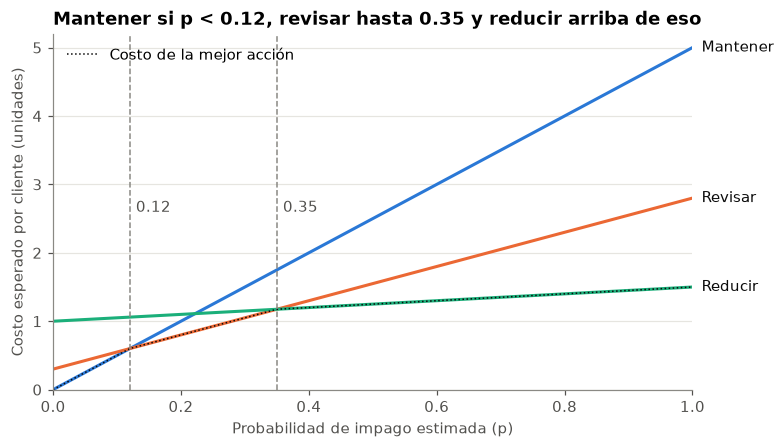

In [3]:
t1, t2 = costos.umbrales_teoricos()
print(f"t1 = {t1:.2f}   t2 = {t2:.2f}")

p = np.linspace(0, 1, 201)
C = costos.costo_esperado_por_accion(p)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for i, (nombre, color) in enumerate(zip(costos.ACCIONES, [AZUL, NARANJA, AQUA])):
    ax.plot(p, C[:, i], color=color, lw=2)
    ax.annotate(nombre, (1.0, C[-1, i]), xytext=(6, 0), textcoords="offset points",
                va="center", color="#0b0b0b")
ax.plot(p, C.min(axis=1), color="#0b0b0b", lw=1, ls=":", label="Costo de la mejor acción")
for t in (t1, t2):
    ax.axvline(t, color=GRIS, lw=1, ls="--")
    ax.annotate(f"{t:.2f}", (t, 2.6), xytext=(4, 0), textcoords="offset points", color="#52514e")
ax.set_xlabel("Probabilidad de impago estimada (p)")
ax.set_ylabel("Costo esperado por cliente (unidades)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 5.2)
ax.legend(loc="upper left", frameon=False)
ax.set_title("Mantener si p < 0.12, revisar hasta 0.35 y reducir arriba de eso")
guardar(fig, "f1_costos_umbrales")
plt.show()

**Qué implica esto para el modelado:**

- Los umbrales 0.12 y 0.35 solo valen si las probabilidades del modelo están **calibradas**. Si se
  entrena con pesos por clase o con remuestreo, las probabilidades se inflan y hay que calibrar
  (o elegir los umbrales directamente minimizando `costos.costo_politica` en validación).
- La métrica para comparar modelos es el **costo promedio por cliente**, más precisión y recall de la
  clase de impago. La exactitud no sirve: decir "nadie impaga" acierta el 78 % y le sale al
  banco más caro que revisar a todos (ver 1.3).

### 1.3 Contra qué hay que ganarle

Sin modelo, el banco solo puede aplicar la misma acción a todos. Con la tasa de impago de entrenamiento (22.1 %):

In [4]:
# Se calcula sobre el mismo entrenamiento de la sección 4 (el test no se mira ni para esto).
y_all = datos.dividir(datos.limpiar(datos.cargar_crudo()))[0][datos.OBJETIVO]
lineas_base = pd.Series(
    {f"{a} a todos": costos.costo_politica_trivial(y_all, i) for i, a in enumerate(costos.ACCIONES)}
    | {"Modelo perfecto (reduce solo a quien impaga)": costos.costo_politica(y_all, y_all.astype(float), t1, t2)},
    name="Costo promedio por cliente",
)
lineas_base.to_frame()

,Costo promedio por cliente
Mantener a todos,1.106
Revisar a todos,0.853
Reducir a todos,1.111
Modelo perfecto (reduce solo a quien impaga),0.332


**La vara es 0.853**: revisar manualmente a todos. Un modelo que no baje de ahí no le sirve al
banco, aunque tenga buen AUC. El mínimo posible (modelo perfecto) es 0.332.

Revisar a todos también es impracticable (30,000 casos para los analistas), así que en el plan de
despliegue habrá que hablar de la **capacidad** de revisión: cuántos casos por mes puede ver el equipo.

### 1.4 ¿Qué tan sensibles son los umbrales a nuestros supuestos?

El supuesto más discutible es el 5:1. Si en la defensa nos preguntan "¿y si fuera 3 o 10?", esta es la
respuesta:

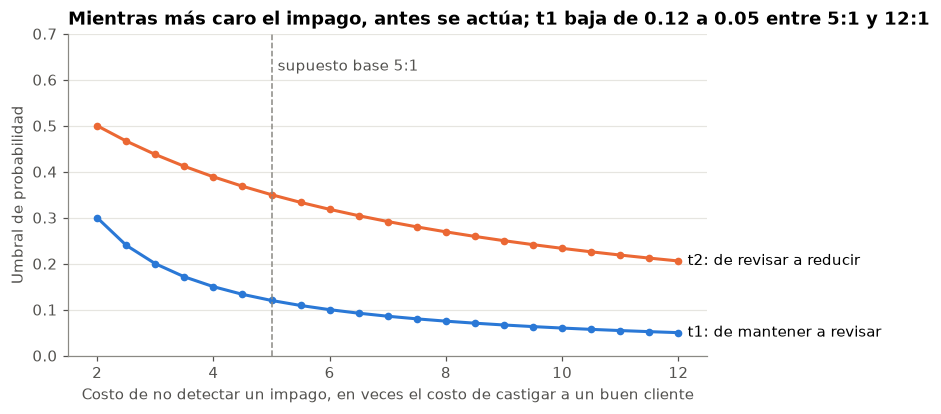

,t1,t2
2.000,0.300,0.500
3.000,0.200,0.437
5.000,0.120,0.350
8.000,0.075,0.269
10.000,0.060,0.233


In [5]:
razones = np.arange(2, 12.5, 0.5)
umb = np.array([costos.umbrales_teoricos(costos.matriz_costos(c_impago=r)) for r in razones])

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(razones, umb[:, 0], color=AZUL, lw=2, marker="o", ms=4)
ax.plot(razones, umb[:, 1], color=NARANJA, lw=2, marker="o", ms=4)
ax.annotate("t1: de mantener a revisar", (razones[-1], umb[-1, 0]), xytext=(6, 0),
            textcoords="offset points", va="center")
ax.annotate("t2: de revisar a reducir", (razones[-1], umb[-1, 1]), xytext=(6, 0),
            textcoords="offset points", va="center")
ax.axvline(costos.C_IMPAGO, color=GRIS, lw=1, ls="--")
ax.annotate("supuesto base 5:1", (costos.C_IMPAGO, 0.62), xytext=(4, 0), textcoords="offset points",
            color="#52514e")
ax.set_xlabel("Costo de no detectar un impago, en veces el costo de castigar a un buen cliente")
ax.set_ylabel("Umbral de probabilidad")
ax.set_ylim(0, 0.7)
ax.set_title("Mientras más caro el impago, antes se actúa; t1 baja de 0.12 a 0.05 entre 5:1 y 12:1")
guardar(fig, "f2_sensibilidad_umbrales")
plt.show()

pd.DataFrame(umb, index=razones, columns=["t1", "t2"]).loc[[2, 3, 5, 8, 10]]

## 2. Datos

Fuente, licencia y fecha de descarga están en [`data/README.md`](../data/README.md). Primero
verificamos que el archivo sea exactamente el que descargamos de UCI:

In [6]:
SHA_ESPERADO = "30c6be3abd8dcfd3e6096c828bad8c2f011238620f5369220bd60cfc82700933"
sha = hashlib.sha256(datos.RUTA_CRUDO.read_bytes()).hexdigest()
assert sha == SHA_ESPERADO, "El archivo crudo no coincide con el descargado de UCI"
print("SHA-256 verificado")

crudo = datos.cargar_crudo()
print(crudo.shape)
crudo.head()

SHA-256 verificado
(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


**Diccionario de variables** (según la documentación de UCI):

| Variable | Qué es |
|---|---|
| `LIMIT_BAL` | Límite de crédito en dólares taiwaneses (NT$), incluye al cliente y sus tarjetas adicionales |
| `SEX` | 1 = hombre, 2 = mujer |
| `EDUCATION` | 1 = posgrado, 2 = universidad, 3 = secundaria, 4 = otros |
| `MARRIAGE` | 1 = casado, 2 = soltero, 3 = otros |
| `AGE` | Edad en años |
| `PAY_0`, `PAY_2`…`PAY_6` | Estado de pago de septiembre (`PAY_0`) a abril (`PAY_6`) de 2005 |
| `BILL_AMT1`…`BILL_AMT6` | Monto facturado de septiembre a abril (NT$) |
| `PAY_AMT1`…`PAY_AMT6` | Monto pagado de septiembre a abril (NT$) |
| `default payment next month` | 1 = impago en octubre de 2005 |

## 3. Limpieza

### 3.1 Revisión de calidad

In [7]:
objetivo_crudo = "default payment next month"
print("Valores faltantes:", int(crudo.isna().sum().sum()))
print("IDs repetidos:   ", int(crudo["ID"].duplicated().sum()))
print("Tipos:", crudo.dtypes.value_counts().to_dict())
print()
for col in ["EDUCATION", "MARRIAGE"]:
    print(crudo.groupby(col)[objetivo_crudo].agg(n="size", tasa_impago="mean").T.round(3), "\n")

Valores faltantes: 0
IDs repetidos:    0
Tipos: {dtype('int64'): 25}

EDUCATION        0          1          2         3       4       5      6
n           14.000 10,585.000 14,030.000 4,917.000 123.000 280.000 51.000
tasa_impago  0.000      0.192      0.237     0.252   0.057   0.064  0.157 

MARRIAGE         0          1          2       3
n           54.000 13,659.000 15,964.000 323.000
tasa_impago  0.093      0.235      0.209   0.260 



**Hallazgos y decisión:**

- **Sin faltantes ni IDs repetidos**, como declara UCI. No hay que imputar nada.
- **`EDUCATION` trae 0, 5 y 6**, que UCI no documenta (345 clientes, 1.2 %). No sabemos qué significan.
  **Decisión:** se agrupan en 4 "Otros". Son muy pocos para estimar algo propio y no tenemos cómo
  interpretarlos.
- **`MARRIAGE` trae 0** (54 clientes). **Decisión:** se agrupa en 3 "Otros", por la misma razón.

In [8]:
pays_crudo = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
conteo = crudo[pays_crudo].apply(pd.Series.value_counts).fillna(0).astype(int)
conteo

,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
-2,2759,3782,4085,4348,4546,4895
-1,5686,6050,5938,5687,5539,5740
0,14737,15730,15764,16455,16947,16286
1,3688,28,4,2,0,0
2,2667,3927,3819,3159,2626,2766
3,322,326,240,180,178,184
4,76,99,76,69,84,49
5,26,25,21,35,17,13
6,11,12,23,5,4,19
7,9,20,27,58,58,46


**El historial de pagos tiene dos problemas de codificación:**

1. **Códigos -2 y 0 no documentados.** UCI documenta -1 = pagó a tiempo y 1–9 = meses de atraso.
   Según lo que explicó el propio autor del dataset en discusiones posteriores, -2 = sin consumo ese
   mes, -1 = pagó el total y 0 = crédito revolvente (pagó el mínimo, sin atraso).
   **Decisión:** se conservan tal cual. Los tres significan "sin atraso", y su orden (sin uso → pagó
   todo → pagó el mínimo) es razonable como escala ordinal. El modelo puede usar la columna como
   número o como categoría; eso se decide en modelado.
2. **El código 1 casi solo aparece en septiembre (`PAY_0`)**: 3,688 clientes en septiembre contra 28 o
   menos en los otros meses. Que un mes de atraso exista en septiembre y prácticamente no exista en
   agosto no es creíble como comportamiento: es casi seguro una **inconsistencia de codificación**
   entre meses. No la podemos corregir sin la documentación del banco. **Decisión:** se deja, y queda
   declarada como límite. Consecuencia: `PAY_1 = 1` y `PAY_2 = 1` no significan lo mismo, así que no
   conviene construir variables que sumen el código entre meses como si fuera la misma escala.

Además, `PAY_0` se llama así pero `BILL_AMT1` y `PAY_AMT1` son el mismo mes. **Decisión:** `PAY_0` se
renombra a `PAY_1` para que los tres índices coincidan.

In [9]:
sin_id = crudo.drop(columns="ID")
dup = sin_id.duplicated(keep=False)
bill_c = [f"BILL_AMT{i}" for i in range(1, 7)]
payamt_c = [f"PAY_AMT{i}" for i in range(1, 7)]
inactivo_c = (crudo[bill_c].eq(0).all(axis=1) & crudo[payamt_c].eq(0).all(axis=1))

print("Filas idénticas (sin contar el ID):", int(sin_id.duplicated().sum()),
      f"sobrantes, {int(dup.sum())} filas involucradas")
print("De esas, cuentas sin ningún movimiento en 6 meses:", int((dup & inactivo_c).sum()))
print()
print("Facturas negativas:", int((crudo[bill_c] < 0).any(axis=1).sum()), "clientes")
print("Montos máximos:", crudo[["LIMIT_BAL"] + bill_c[:1] + payamt_c[:2]].max().to_dict())
print("Edad:", crudo["AGE"].min(), "a", crudo["AGE"].max())

Filas idénticas (sin contar el ID): 35 sobrantes, 70 filas involucradas
De esas, cuentas sin ningún movimiento en 6 meses: 60

Facturas negativas: 1930 clientes
Montos máximos: {'LIMIT_BAL': 1000000, 'BILL_AMT1': 964511, 'PAY_AMT1': 873552, 'PAY_AMT2': 1684259}
Edad: 21 a 79


- **35 filas son idénticas a otra salvo por el ID.** 60 de las 70 filas involucradas son cuentas sin
  ningún movimiento en seis meses (factura 0 y pago 0 todos los meses); las otras 10 son cargos fijos
  que se pagan completos cada mes. Que dos clientes distintos con el mismo límite, sexo, educación,
  estado civil y edad no hayan usado la tarjeta es perfectamente posible.
  **Decisión:** **no se eliminan.** Son clientes distintos (IDs distintos) con perfiles comunes; borrarlos
  sesgaría la muestra contra las cuentas inactivas. Son 35 de 30,000, así que el efecto de que alguno
  quede repetido entre train y test es despreciable.
- **1,930 clientes tienen facturas negativas.** Es saldo a favor (pagaron de más). **Decisión:** se
  conservan; no es un error.
- Los montos tienen colas largas (pagos de hasta 1.7 millones) pero son consistentes con límites de
  hasta 1 millón. **Decisión:** no se recortan atípicos; se trata en modelado (ver EDA, sección 5.6).
- Edad de 21 a 79: sin valores imposibles.

### 3.2 Aplicar la limpieza

Las reglas están en `src/datos.limpiar` para que modelado use exactamente las mismas.

In [10]:
df = datos.limpiar(crudo)
print(df.shape)
print("EDUCATION:", df["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE: ", df["MARRIAGE"].value_counts().sort_index().to_dict())
assert len(df) == 30_000
df.head()

(30000, 24)
EDUCATION: {1: 10585, 2: 14030, 3: 4917, 4: 468}
MARRIAGE:  {1: 13659, 2: 15964, 3: 377}


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
ID,,,,,,,,,,,,,,,,,,,,,
1,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
2,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
5,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 4. Split entrenamiento / prueba

Se separa **ahora, antes del EDA**, para que nada de lo que veamos en los datos influya con información
del conjunto de prueba. 80 % entrenamiento, 20 % prueba, **estratificado** por la variable objetivo y
con semilla fija (42).

- La validación de hiperparámetros se hace con validación cruzada **dentro** de `train.csv`.
- `test.csv` se abre **una sola vez**, al final, para el número que se reporta.

In [11]:
train, test = datos.dividir(df)
assert train.index.intersection(test.index).empty
assert len(train) + len(test) == len(df)

train.to_csv(datos.DIR_PROCESADO / "train.csv")
test.to_csv(datos.DIR_PROCESADO / "test.csv")

pd.DataFrame({
    "clientes": [len(train), len(test)],
    "impagos": [int(train[datos.OBJETIVO].sum()), int(test[datos.OBJETIVO].sum())],
    "tasa de impago": [train[datos.OBJETIVO].mean(), test[datos.OBJETIVO].mean()],
}, index=["train", "test"])

,clientes,impagos,tasa de impago
train,24000,5309,0.221
test,6000,1327,0.221


**De aquí en adelante todo el EDA usa solo `train`.**

## 5. Análisis exploratorio (solo entrenamiento)

In [12]:
y = train[datos.OBJETIVO]
TASA = y.mean()
print(f"Tasa de impago en entrenamiento: {pct(TASA)} ({int(y.sum()):,} de {len(y):,})")


def tasa_por(serie, minimo=0):
    t = y.groupby(serie, observed=True).agg(n="size", tasa="mean")
    return t[t["n"] >= minimo]


def barras_tasa(ax, tabla, etiquetas=None, resaltar=None, color=AZUL):
    x = np.arange(len(tabla))
    colores = [NARANJA if resaltar is not None and resaltar(k) else color for k in tabla.index]
    ax.bar(x, tabla["tasa"], color=colores, width=0.7)
    ax.axhline(TASA, color=GRIS, lw=1, ls="--")
    for xi, (tasa, n) in enumerate(zip(tabla["tasa"], tabla["n"])):
        ax.annotate(f"{100 * tasa:.0f} %", (xi, tasa), xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=9)
    ax.set_xticks(x, etiquetas if etiquetas is not None else tabla.index)
    ax.yaxis.set_major_formatter(lambda v, _: f"{100 * v:.0f} %")

Tasa de impago en entrenamiento: 22.1 % (5,309 de 24,000)


### 5.1 Desbalance

El 22.1 % de los clientes impaga. No es un desbalance extremo, pero sí suficiente para que la
exactitud engañe (un modelo que diga "nadie impaga" acierta el 78 %).

**Decisión:** métricas sobre la clase de impago (precisión, recall, curva PR) y costo esperado. Probar
pesos por clase antes que remuestreo, como dice la propuesta.

### 5.2 El historial de pagos es la señal más fuerte

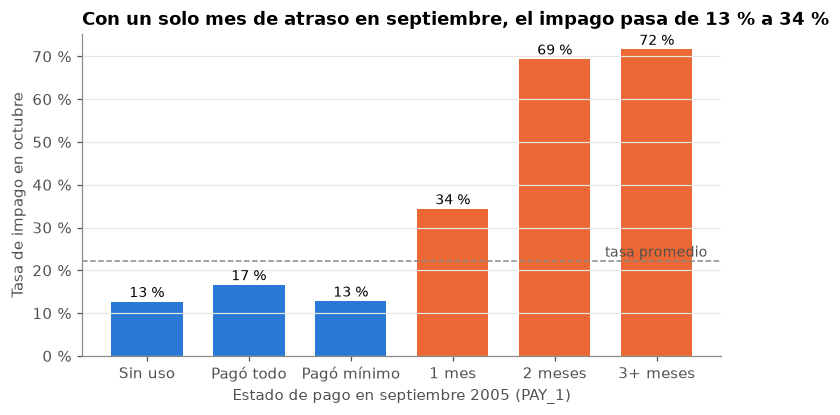

,n,tasa
PAY_1,,
-2,2198,0.127
-1,4527,0.166
0,11781,0.128
1,3000,0.344
2,2138,0.694
3,356,0.716


In [13]:
ultimo = train["PAY_1"].clip(upper=3)
tabla = tasa_por(ultimo)
etq = {-2: "Sin uso", -1: "Pagó todo", 0: "Pagó mínimo", 1: "1 mes", 2: "2 meses", 3: "3+ meses"}

fig, ax = plt.subplots(figsize=(7.5, 3.8))
barras_tasa(ax, tabla, [etq[k] for k in tabla.index], resaltar=lambda k: k >= 1)
ax.annotate("tasa promedio", (len(tabla) - 0.5, TASA), xytext=(0, 3), textcoords="offset points",
            ha="right", color="#52514e", fontsize=9)
ax.set_xlabel("Estado de pago en septiembre 2005 (PAY_1)")
ax.set_ylabel("Tasa de impago en octubre")
ax.set_title("Con un solo mes de atraso en septiembre, el impago pasa de 13 % a 34 %")
guardar(fig, "f3_impago_por_pay1")
plt.show()
tabla

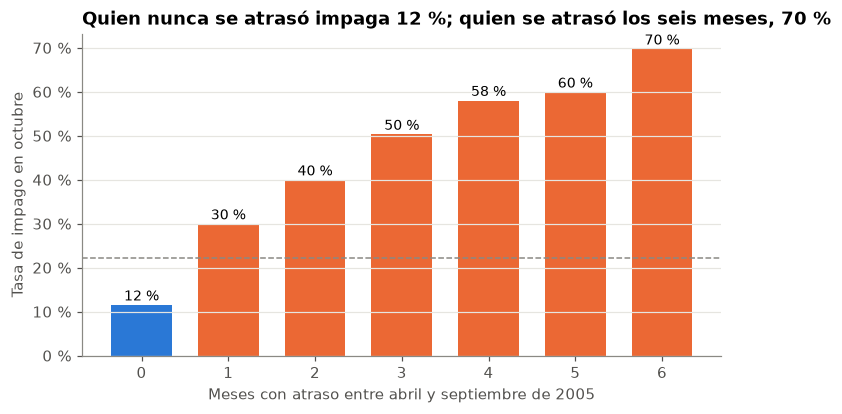

,n,tasa
0,15896,0.115
1,3572,0.300
2,1532,0.399
3,936,0.503
4,767,0.580
5,237,0.599
6,1060,0.697


In [14]:
meses_atraso = (train[datos.PAY] > 0).sum(axis=1)
tabla = tasa_por(meses_atraso)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
barras_tasa(ax, tabla, resaltar=lambda k: k >= 1)
ax.set_xlabel("Meses con atraso entre abril y septiembre de 2005")
ax.set_ylabel("Tasa de impago en octubre")
ax.set_title("Quien nunca se atrasó impaga 12 %; quien se atrasó los seis meses, 70 %")
guardar(fig, "f4_impago_por_meses_atraso")
plt.show()
tabla

**Hallazgo.** El comportamiento de pago reciente separa mucho más que cualquier otra cosa: sin atrasos
la tasa es ~12 %; con un mes de atraso en septiembre sube a ~34 %; con atrasos en los seis meses, ~70 %.
Los códigos -2, -1 y 0 tienen tasas parecidas entre sí (todas bajo el promedio), lo que respalda
tratarlos como "sin atraso".

**Decisión:**
- La regresión logística necesita esta señal en una forma que pueda usar: además de las columnas
  `PAY_*` crudas, conviene probar **número de meses con atraso** y un indicador de **atraso en el último
  mes**. Ambas variables son monótonas con el riesgo, que es lo que un modelo lineal aprovecha bien.
- Un modelo de árboles puede descubrir los cortes solo; ahí las `PAY_*` crudas bastan.

### 5.3 Límite de crédito y uso de la línea

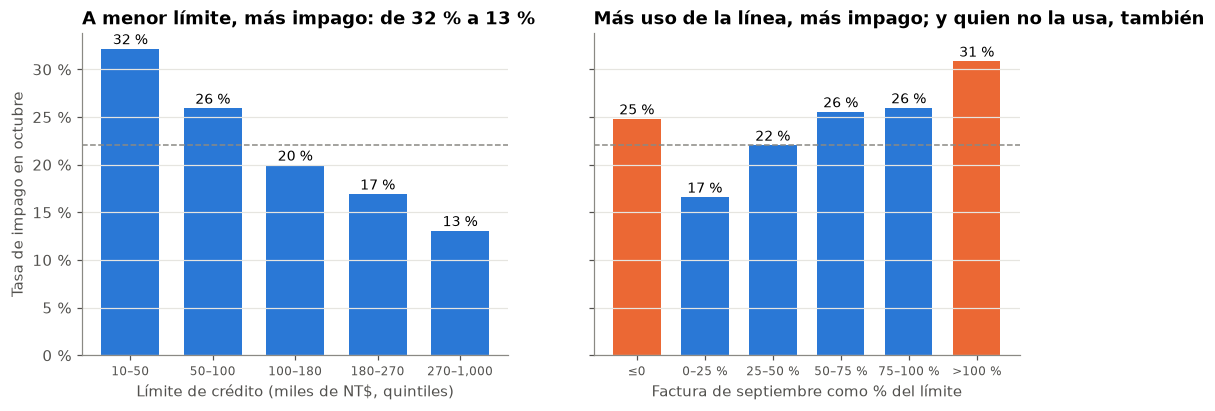

n  tasa
límite          (9999.999, 50000.0]    6146 0.322
                (50000.0, 100000.0]    3819 0.259
                (100000.0, 180000.0]   4922 0.200
                (180000.0, 270000.0]   4380 0.169
                (270000.0, 1000000.0]  4733 0.131
uso de la línea ≤0                     2080 0.248
                0–25 %                 9136 0.166
                25–50 %                2885 0.220
                50–75 %                2869 0.255
                75–100 %               5345 0.260
                >100 %                 1685 0.309

In [15]:
quintil = pd.qcut(train["LIMIT_BAL"], 5)
tabla = tasa_por(quintil)
etiquetas_q = ["10–50", "50–100", "100–180", "180–270", "270–1,000"]
assert [int(i.right) for i in tabla.index] == [50_000, 100_000, 180_000, 270_000, 1_000_000]

uso = (train["BILL_AMT1"] / train["LIMIT_BAL"])
tramos_uso = pd.cut(uso, [-np.inf, 0, 0.25, 0.5, 0.75, 1.0, np.inf],
                    labels=["≤0", "0–25 %", "25–50 %", "50–75 %", "75–100 %", ">100 %"])
tabla_uso = tasa_por(tramos_uso)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
barras_tasa(axs[0], tabla, etiquetas_q)
axs[0].set_xlabel("Límite de crédito (miles de NT$, quintiles)")
axs[0].set_ylabel("Tasa de impago en octubre")
axs[0].set_title("A menor límite, más impago: de 32 % a 13 %")
barras_tasa(axs[1], tabla_uso, resaltar=lambda k: k in ("≤0", ">100 %"))
for ax in axs:
    ax.tick_params(axis="x", labelsize=8)
axs[1].set_xlabel("Factura de septiembre como % del límite")
axs[1].set_title("Más uso de la línea, más impago; y quien no la usa, también")
guardar(fig, "f5_limite_y_uso")
plt.show()
pd.concat({"límite": tabla, "uso de la línea": tabla_uso})

**Hallazgo.** El límite baja el riesgo de forma monótona (el banco ya le da menos línea a quien
considera más riesgoso, así que el límite resume parte de la evaluación previa del banco). El uso de la
línea no es monótono: quienes tienen factura cero o negativa también impagan más que quienes usan
una parte pequeña (25 % contra 17 %; ver 5.5). Desde ahí, más uso, más impago (de 17 % a 31 %).

**Decisión:** crear **uso de la línea** (`BILL_AMT1 / LIMIT_BAL`) como variable candidata. Para la
regresión logística, por no ser monótona, conviene tramarla o dejar que el modelo de árboles la tome.

### 5.4 Variables demográficas

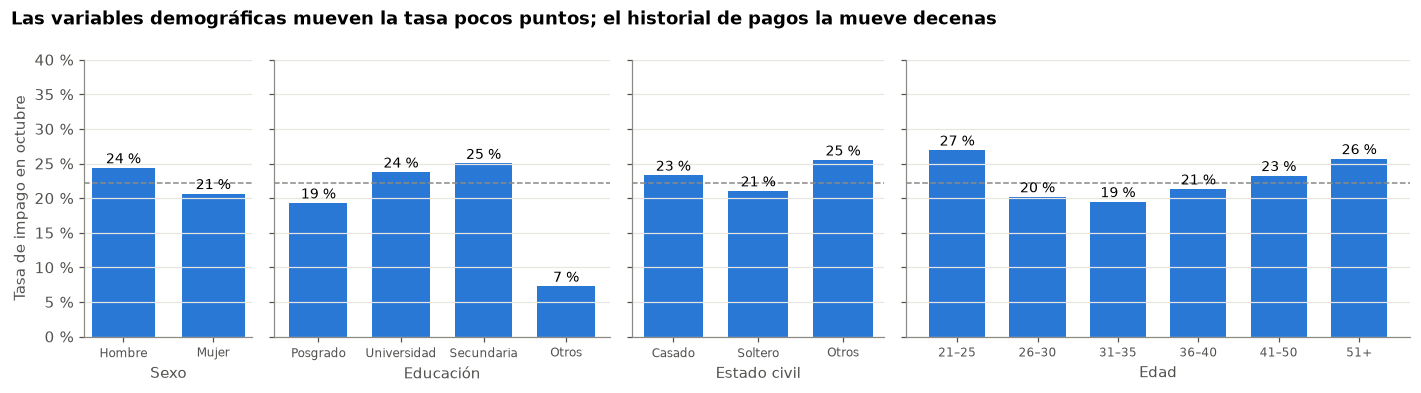

n  tasa
Sexo         Hombre        9486 0.244
             Mujer        14514 0.206
Educación    Posgrado      8455 0.193
             Universidad  11256 0.238
             Secundaria    3903 0.250
             Otros          386 0.073
Estado civil Casado       10892 0.233
             Soltero      12806 0.210
             Otros          302 0.255
Edad         21–25         3104 0.269
             26–30         5728 0.202
             31–35         4718 0.195
             36–40         3890 0.213
             41–50         4762 0.232
             51+           1798 0.257

In [16]:
tramos_edad = pd.cut(train["AGE"], [20, 25, 30, 35, 40, 50, 80],
                     labels=["21–25", "26–30", "31–35", "36–40", "41–50", "51+"])
paneles = [
    ("Sexo", tasa_por(train["SEX"].map(datos.ETIQUETAS["SEX"]))),
    ("Educación", tasa_por(train["EDUCATION"].map(datos.ETIQUETAS["EDUCATION"])).reindex(
        ["Posgrado", "Universidad", "Secundaria", "Otros"])),
    ("Estado civil", tasa_por(train["MARRIAGE"].map(datos.ETIQUETAS["MARRIAGE"])).reindex(
        ["Casado", "Soltero", "Otros"])),
    ("Edad", tasa_por(tramos_edad)),
]
fig, axs = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True,
                        gridspec_kw={"width_ratios": [2, 4, 3, 6]})
for ax, (nombre, t) in zip(axs, paneles):
    barras_tasa(ax, t)
    ax.set_xlabel(nombre)
    ax.tick_params(axis="x", labelsize=8)
axs[0].set_ylabel("Tasa de impago en octubre")
axs[0].set_ylim(0, 0.4)
fig.suptitle("Las variables demográficas mueven la tasa pocos puntos; el historial de pagos la mueve decenas",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
guardar(fig, "f6_demograficas")
plt.show()
pd.concat({n: t for n, t in paneles})

**Hallazgo.** Hombres impagan algo más que mujeres (~24 % contra ~21 %); secundaria más que posgrado
(~25 % contra ~19 %); la edad tiene forma de U suave (más impago en los extremos). Ninguna diferencia
se acerca a lo que separa el historial de pagos. "Otros" en educación tiene una tasa muy baja (~7 %),
pero son pocos clientes y ni siquiera sabemos qué agrupa.

**Decisión (abierta para modelado):** sexo, edad y estado civil son **atributos protegidos**. Usarlos
para reducirle el límite a alguien es discutible legal y éticamente, y aportan poco. Proponemos:
- Entrenar **sin** `SEX` y `MARRIAGE` y comparar contra el modelo con ellas. Si el costo casi no cambia,
  quedarse con el modelo sin ellas.
- **Con o sin ellas en el modelo**, las conservamos en los datos para el análisis de errores por grupo
  que pide la evaluación (edad, sexo, educación).

### 5.5 Cuentas sin movimiento: una anomalía

In [17]:
inactivo = train[datos.BILL].eq(0).all(axis=1) & train[datos.PAY_AMT].eq(0).all(axis=1)
neg = (train[datos.BILL] < 0).any(axis=1)
pd.DataFrame({
    "clientes": [int(inactivo.sum()), int(neg.sum()), len(train)],
    "tasa de impago": [y[inactivo].mean(), y[neg].mean(), TASA],
}, index=["Sin facturas ni pagos en 6 meses", "Con alguna factura negativa", "Todos"])

,clientes,tasa de impago
Sin facturas ni pagos en 6 meses,642,0.374
Con alguna factura negativa,1553,0.157
Todos,24000,0.221


**Hallazgo.** Los clientes que **no facturaron ni pagaron nada en seis meses impagan alrededor de 37 %**,
bastante más que el promedio. No tiene sentido que alguien sin saldo "deje de pagar". Puede ser que el
dato de impago incluya otras deudas, que la cuenta esté congelada, o un problema de captura. No lo
podemos verificar.

**Decisión:** no se eliminan (serían clientes que el modelo igual vería en producción), pero se agrega
un indicador `INACTIVO` como variable candidata, y queda declarado como límite: **no entendemos qué
significa el impago para estos clientes**. Es buena pregunta para la defensa.

### 5.6 Montos: colas largas y meses muy correlacionados

In [18]:
montos = datos.BILL + datos.PAY_AMT
print("Asimetría (skew) de los montos:")
print(train[montos + ["LIMIT_BAL"]].skew().round(1).to_dict())
print()
print("Correlación entre facturas de meses distintos:")
train[datos.BILL].corr().round(2)

Asimetría (skew) de los montos:
{'BILL_AMT1': 2.7, 'BILL_AMT2': 2.7, 'BILL_AMT3': 2.7, 'BILL_AMT4': 2.8, 'BILL_AMT5': 2.9, 'BILL_AMT6': 2.9, 'PAY_AMT1': 15.3, 'PAY_AMT2': 21.1, 'PAY_AMT3': 18.6, 'PAY_AMT4': 12.4, 'PAY_AMT5': 11.1, 'PAY_AMT6': 10.5, 'LIMIT_BAL': 1.0}

Correlación entre facturas de meses distintos:


,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6
BILL_AMT1,1.000,0.950,0.900,0.860,0.830,0.800
BILL_AMT2,0.950,1.000,0.940,0.890,0.860,0.830
BILL_AMT3,0.900,0.940,1.000,0.930,0.890,0.860
BILL_AMT4,0.860,0.890,0.930,1.000,0.940,0.900
BILL_AMT5,0.830,0.860,0.890,0.940,1.000,0.950
BILL_AMT6,0.800,0.830,0.860,0.900,0.950,1.000


**Hallazgo.**
- Pagos y facturas tienen colas muy largas (asimetría de 10 a 21 en los pagos, ~3 en las facturas): unos pocos clientes
  mueven montos enormes.
- Las facturas de meses consecutivos tienen correlación de 0.93–0.95, e incluso abril con septiembre
  llega a 0.80: casi repiten la misma información.

**Decisión:**
- Para la regresión logística, transformar los montos con `log1p` (los pagos son ≥ 0; las facturas
  pueden ser negativas, así que necesitan `sign(x)·log1p(|x|)`) y estandarizar. Los árboles no lo
  necesitan.
- La colinealidad entre meses justifica usar **regularización** (como dice la propuesta) y hace que los
  coeficientes individuales por mes **no** se puedan interpretar uno por uno.

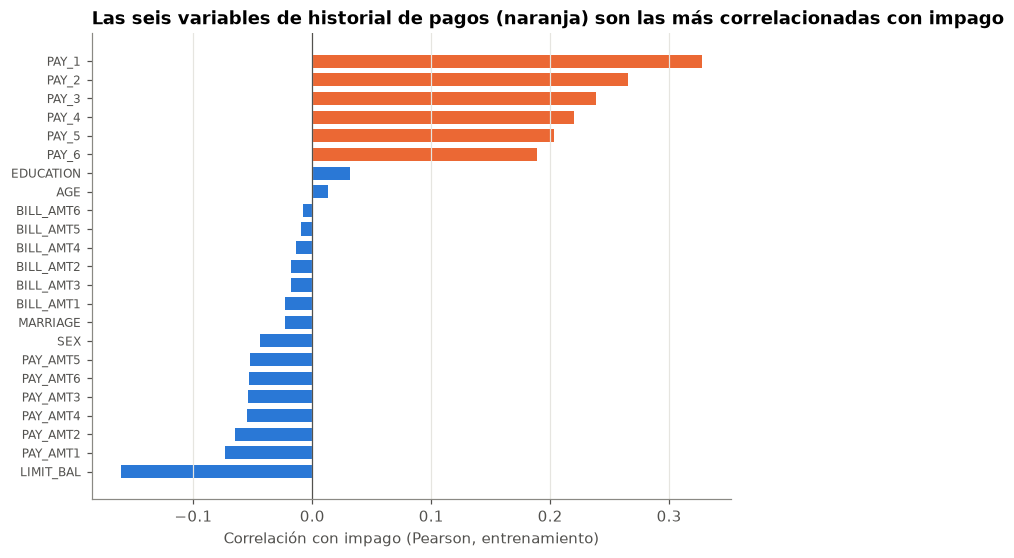

In [19]:
corr = train.drop(columns=datos.OBJETIVO).corrwith(y).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 5.5))
colores = [NARANJA if c.startswith("PAY_") and "AMT" not in c else AZUL for c in corr.index]
ax.barh(corr.index, corr.values, color=colores, height=0.7)
ax.axvline(0, color="#52514e", lw=0.8)
ax.grid(axis="x", color="#e6e5e0")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Correlación con impago (Pearson, entrenamiento)")
ax.set_title("Las seis variables de historial de pagos (naranja) son las más correlacionadas con impago")
ax.tick_params(axis="y", labelsize=8)
guardar(fig, "f7_correlacion_objetivo")
plt.show()

### 5.7 Matriz de correlación completa

La gráfica anterior mira cada variable contra el impago. La matriz completa muestra además qué
variables **repiten información entre sí**, que es lo que importa para elegir variables y para
entender por qué hace falta regularizar. Usamos Spearman (por rangos) porque las `PAY_*` son códigos
ordinales y los montos tienen colas muy largas; Pearson se deja llevar por los valores extremos.

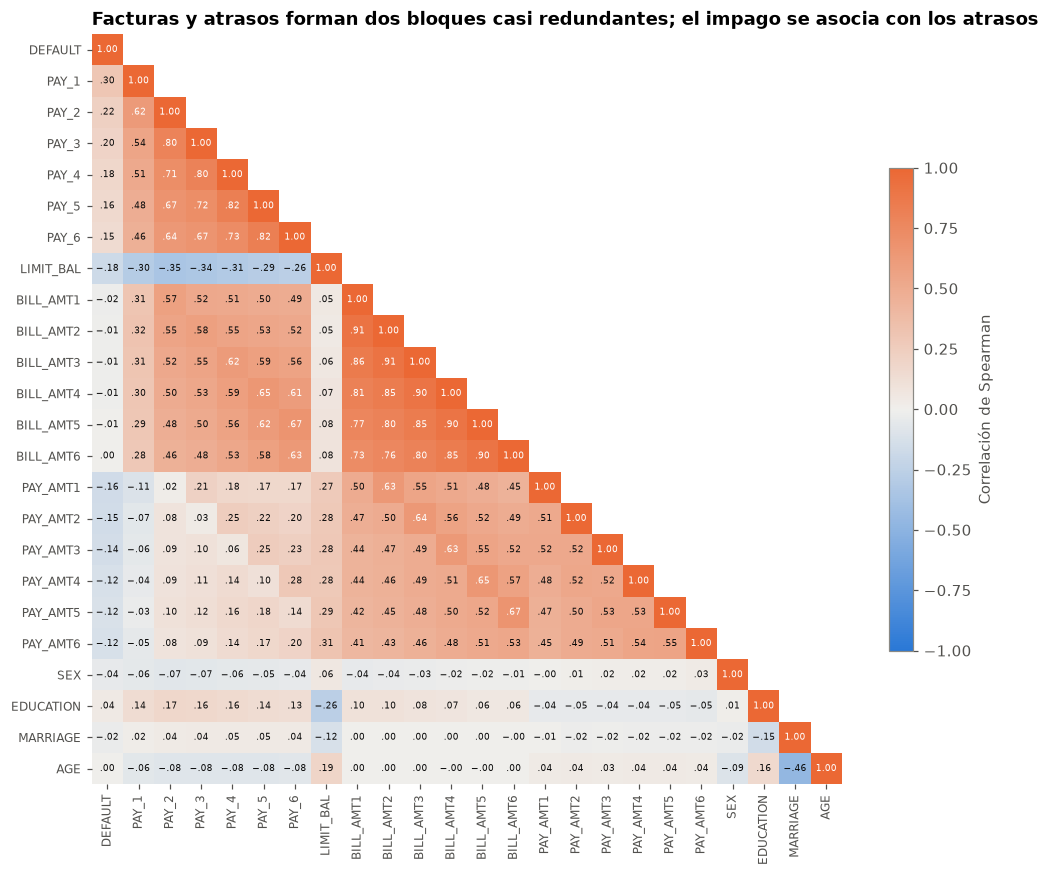

Correlación (Spearman) con impago, de mayor a menor en valor absoluto:


,rho
PAY_1,0.297
PAY_2,0.219
PAY_3,0.199
PAY_4,0.179
LIMIT_BAL,-0.178
PAY_AMT1,-0.162
PAY_5,0.159
PAY_AMT2,-0.151
PAY_6,0.146
PAY_AMT3,-0.142


In [20]:
from matplotlib.colors import LinearSegmentedColormap

orden = ([datos.OBJETIVO] + datos.PAY + ["LIMIT_BAL"] + datos.BILL + datos.PAY_AMT + datos.DEMOGRAFICAS)
corr_s = train[orden].corr(method="spearman")
mascara = np.triu(np.ones_like(corr_s, dtype=bool), k=1)
divergente = LinearSegmentedColormap.from_list("azul_gris_naranja", [AZUL, "#f0efec", NARANJA])

fig, ax = plt.subplots(figsize=(11, 9.5))
datos_m = np.ma.masked_array(corr_s.values, mascara)
im = ax.imshow(datos_m, cmap=divergente, vmin=-1, vmax=1)
for i in range(len(orden)):
    for j in range(i + 1):
        v = corr_s.iat[i, j]
        ax.text(j, i, f"{v:.2f}".replace("0.", ".").replace("-.", "−."), ha="center", va="center",
                fontsize=6, color="white" if abs(v) > 0.6 else "#0b0b0b")
ax.set_xticks(range(len(orden)), orden, rotation=90, fontsize=8)
ax.set_yticks(range(len(orden)), orden, fontsize=8)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.6, label="Correlación de Spearman")
ax.set_title("Facturas y atrasos forman dos bloques casi redundantes; el impago se asocia con los atrasos")
guardar(fig, "f8_matriz_correlacion")
plt.show()

print("Correlación (Spearman) con impago, de mayor a menor en valor absoluto:")
corr_s[datos.OBJETIVO].drop(datos.OBJETIVO).sort_values(key=abs, ascending=False).round(3).to_frame("rho")

**Hallazgo.**
- Con Spearman se ve lo mismo que con Pearson: los atrasos (`PAY_*`) son lo que más se asocia con
  impago, y luego el límite de crédito y los montos pagados (con signo negativo: quien paga más, impaga
  menos).
- Hay **dos bloques redundantes**: las seis facturas entre sí y los seis estados de pago entre sí. Los
  pagos de distintos meses se parecen bastante menos entre sí.
- Las demográficas casi no se relacionan con el impago. Entre ellas, la edad va con el estado civil
  (−0.46: los casados son mayores) y más educación va con más límite (−0.26, porque 1 = posgrado).
  Ojo: `SEX` y `MARRIAGE` son categorías sin orden, así que su correlación solo es orientativa.

**Decisión (para modelado):** que una variable tenga correlación baja con el objetivo **no** es razón
para sacarla; la correlación solo mide relación lineal y monótona (el uso de la línea, que tiene forma
de U, lo muestra). La selección de variables y los hiperparámetros se deciden con **validación cruzada
sobre el costo**, no con esta matriz. La matriz sirve para dos cosas: justificar la regularización (por
los bloques redundantes) y no leer los coeficientes de la logística mes por mes.

La **matriz de confusión** no es parte del EDA porque necesita predicciones. Para nuestro problema es
de 3 × 2 (acción tomada contra lo que pasó en realidad) y se arma con `costos.tabla_decisiones`.

## 6. Resumen: hallazgos que cambiaron decisiones

| # | Hallazgo | Decisión |
|---|---|---|
| 1 | Los dos errores no cuestan lo mismo (supuesto 5:1) | Métrica principal: costo promedio por cliente. Umbrales teóricos 0.12 y 0.35, con probabilidades calibradas |
| 2 | Sin modelo, lo mejor es revisar a todos: costo 0.853 | Es la vara que el modelo tiene que superar |
| 3 | 22 % de impago | Exactitud descartada. Pesos por clase antes que remuestreo |
| 4 | `EDUCATION` 0/5/6 y `MARRIAGE` 0 no documentados | Agrupados en "Otros" |
| 5 | `PAY_*` -2/-1/0 son "sin atraso" con tasas parecidas | Se conservan sin recodificar; si entran como número o como categoría se decide en modelado |
| 6 | El código 1 casi solo existe en septiembre | Inconsistencia declarada como límite; no sumar códigos entre meses |
| 7 | 35 duplicados, casi todos cuentas sin movimiento | No se eliminan: son clientes distintos |
| 8 | El historial de pagos domina la señal | Variables candidatas: meses con atraso y atraso en el último mes |
| 9 | Límite monótono; uso de la línea en U | Variable candidata: uso de la línea |
| 10 | Demográficas aportan poco y son sensibles | Comparar modelo con y sin `SEX`/`MARRIAGE`; conservarlas para análisis de errores |
| 11 | Cuentas inactivas impagan 37 % | Indicador `INACTIVO`; límite declarado |
| 12 | Montos con colas largas y meses colineales | `log1p` + estandarizar para la logística; regularización |
| 13 | Matriz de correlación: dos bloques redundantes (facturas y atrasos) | Regularización; selección de variables por validación cruzada, no por correlación |

## 7. Entrega a la fase de modelado

**Archivos:**
- `data/processed/train.csv`: 24,000 clientes limpios, índice `ID`. Aquí se hace todo (incluida la
  validación cruzada).
- `data/processed/test.csv`: 6,000 clientes. **Se abre una vez**, al final.
- `figures/`: las gráficas de esta fase, listas para las diapositivas.

**Código:**
```python
from src import datos, costos

train = datos.cargar_train()
X, y = train.drop(columns=datos.OBJETIVO), train[datos.OBJETIVO]

t1, t2 = costos.umbrales_teoricos()               # 0.12 y 0.35
costos.costo_politica(y_val, p_val, t1, t2)       # costo promedio por cliente
costos.costo_politica_trivial(y_val, 1)           # línea base: revisar a todos
costos.tabla_decisiones(y_val, p_val, t1, t2)     # matriz de confusión de 3 acciones
```

**Pendiente para modelado (no lo decidimos aquí a propósito).** Ya se resolvió en el notebook 02, con
validación cruzada sobre el costo:
- Si las `PAY_*` entran como número o como categoría. → **Categoría** (costo 0.760 → 0.727, gana en las
  5 rondas; notebook 02, sección 2).
- Si las variables candidatas (meses con atraso, atraso en el último mes, uso de la línea, `INACTIVO`)
  mejoran el costo en validación cruzada. → Con `PAY_*` como categoría la mejora es mínima (0.727 →
  0.725); se dejan porque no estorban (sección 2).
- Con o sin `SEX` y `MARRIAGE`. → **Sin ellas**: quitarlas sube el costo solo 0.0015 (0.2 %; sección 8).
- Calibración de probabilidades antes de aplicar los umbrales. → La logística **sin pesos por clase**
  ya está calibrada (probabilidad media 0.221). Con pesos por clase, como sugería el hallazgo 3, las
  probabilidades se inflan y el costo sube a 0.868, peor que la vara; por eso el modelo final va sin
  pesos (sección 4).

## 8. Lo que esta fase no puede concluir

- Los costos son **supuestos nuestros**. Cambian los umbrales (sección 1.4); no cambian la lógica.
- Los datos son de **un banco, un país y 2005**. Las tasas por grupo describen a esos clientes, no a
  los de otro banco ni de hoy.
- No sabemos qué significan los códigos no documentados ni el impago de las cuentas sin movimiento.
- Las diferencias por sexo, edad o educación son **asociaciones**, no causas.